# Modélisation du prix d'évaluation  de sinistre


In [1]:
import pandas as pd 
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [6]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [9]:
initial_train_set = pd.read_csv("C:/Users/papam/Documents/Cours_Cytech/ING3/Data Science/PricingPrimeAssurance/data/train.csv", sep=",")   
sinistres = initial_train_set[initial_train_set["nombre_sinistres"] > 0].copy()

In [10]:
print(sinistres.shape)
print(sinistres["montant_sinistre"].describe())

(2917, 33)
count     2917.000000
mean      1771.843401
std       1463.954673
min        600.600000
25%        959.970000
50%       1236.000000
75%       2169.100000
max      21826.960000
Name: montant_sinistre, dtype: float64


In [11]:


sinistres["departement"] = sinistres["code_postal"].astype(str).str.zfill(5).str[:2]
log_m = np.log1p(sinistres["montant_sinistre"])

# Variables quantitatives
quanti_m = ["prix_vehicule", "anciennete_vehicule", "din_vehicule", "poids_vehicule",
            "vitesse_vehicule", "cylindre_vehicule", "age_conducteur1", "anciennete_permis1", "bonus"]
print(sinistres[quanti_m].corrwith(log_m, method="spearman").sort_values(key=abs, ascending=False).round(3))

# Variables qualitatives : Kruskal-Wallis
quali_m = ["type_contrat", "marque_vehicule", "type_vehicule", "essence_vehicule",
           "utilisation", "departement", "freq_paiement", "paiement"]
res = []
for c in quali_m:
    groupes = [g for _, g in log_m.groupby(sinistres[c]) if len(g) >= 10]
    _, p = stats.kruskal(*groupes)
    res.append((c, sinistres[c].nunique(), round(p, 4)))
print(pd.DataFrame(res, columns=["variable", "nb_modalites", "p_value"]).sort_values("p_value"))

anciennete_vehicule   -0.085
cylindre_vehicule     -0.043
poids_vehicule        -0.030
prix_vehicule         -0.029
anciennete_permis1    -0.022
din_vehicule          -0.019
age_conducteur1       -0.016
bonus                  0.014
vitesse_vehicule       0.008
dtype: float64
           variable  nb_modalites  p_value
0      type_contrat             4   0.0000
3  essence_vehicule             3   0.0582
2     type_vehicule             2   0.1865
7          paiement             2   0.1993
6     freq_paiement             4   0.2211
5       departement            95   0.3190
4       utilisation             4   0.3347
1   marque_vehicule            46   0.5645


In [8]:
print(sinistres.groupby("type_contrat")["montant_sinistre"].agg(["mean", "median", "count"]).round(0))

                mean  median  count
type_contrat                       
Maxi          1845.0  1296.0   2421
Median1       1513.0  1236.0    139
Median2       1367.0  1236.0    283
Mini          1412.0  1236.0     74


                     pearson_montant  pearson_log  spearman
anciennete_vehicule           -0.111       -0.110    -0.085
cylindre_vehicule             -0.011       -0.036    -0.043
poids_vehicule                 0.009       -0.011    -0.030
prix_vehicule                  0.020       -0.006    -0.029
anciennete_permis1            -0.055       -0.035    -0.022
din_vehicule                   0.024       -0.006    -0.019
age_conducteur1               -0.044       -0.027    -0.016
bonus                          0.021        0.019     0.014
vitesse_vehicule               0.034        0.016     0.008

--- prix_vehicule ---
                     montant_moyen  montant_median    n  log_moyen
prix_vehicule                                                     
(1547.999, 12900.0]        1715.49         1236.00  587       7.28
(12900.0, 16950.0]         1767.63         1236.00  582       7.29
(16950.0, 20950.0]         1840.59         1240.89  585       7.30
(20950.0, 26679.6]         1796.48        

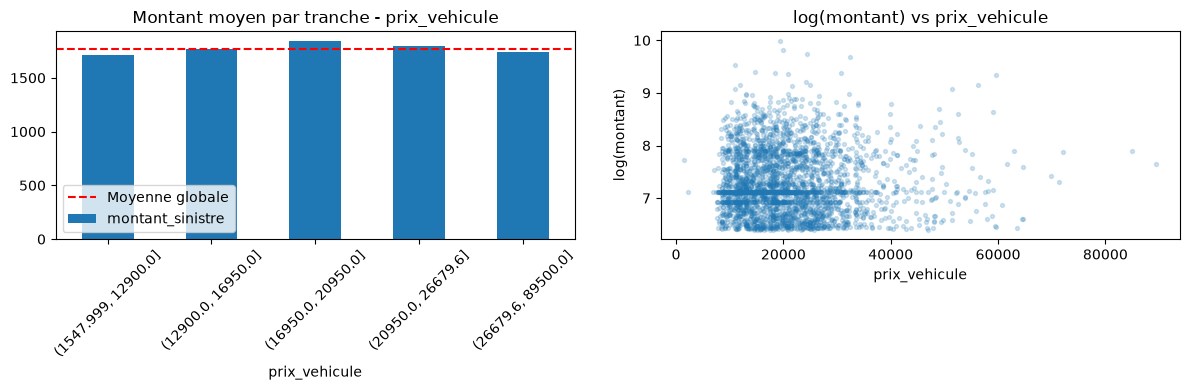

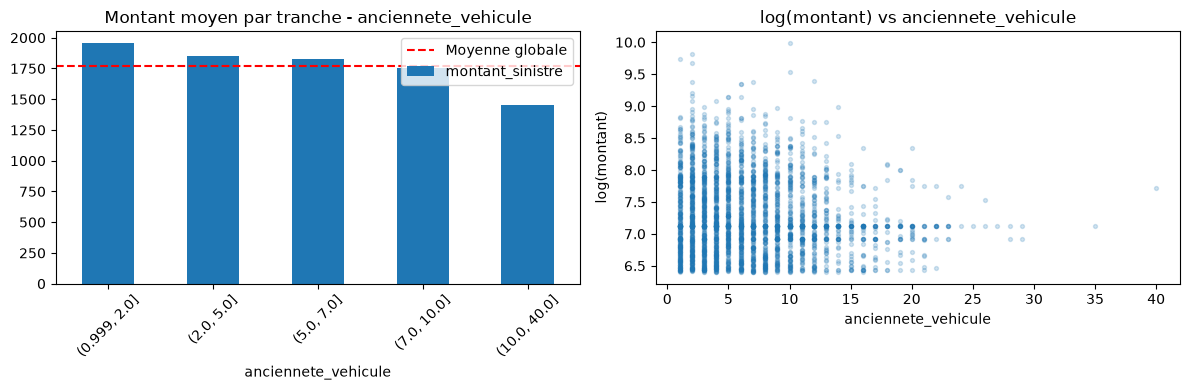

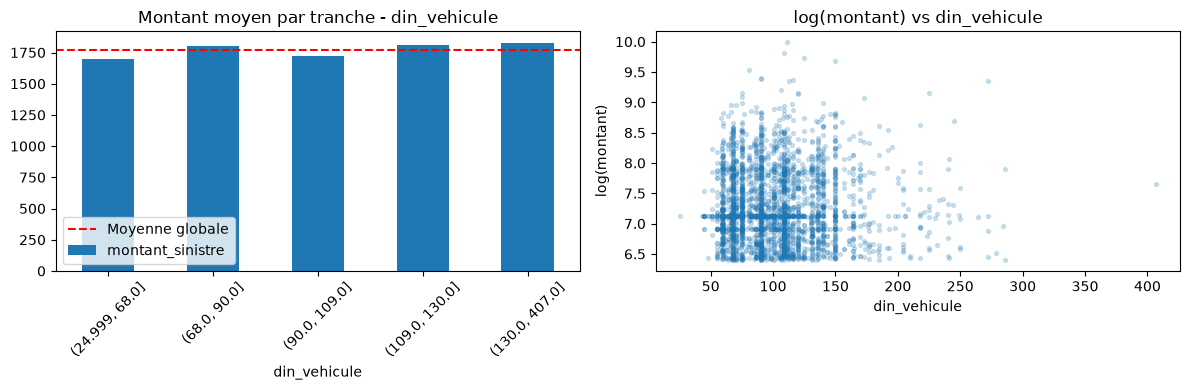

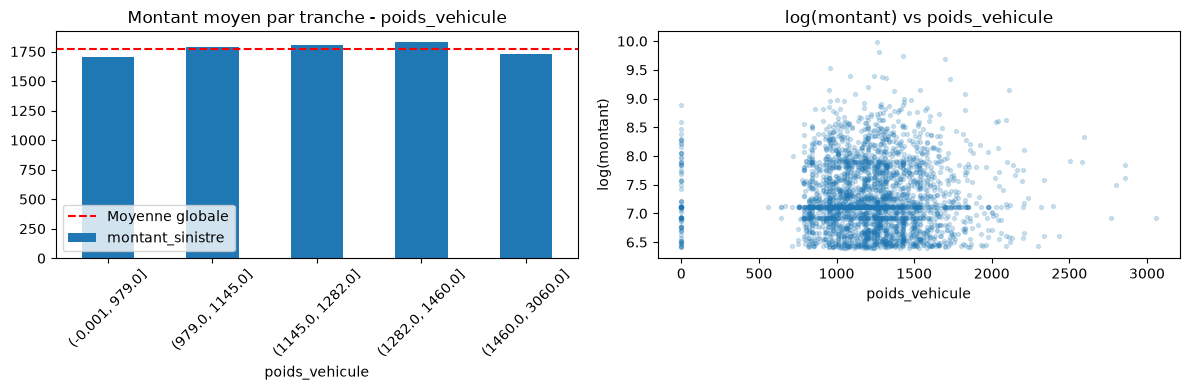

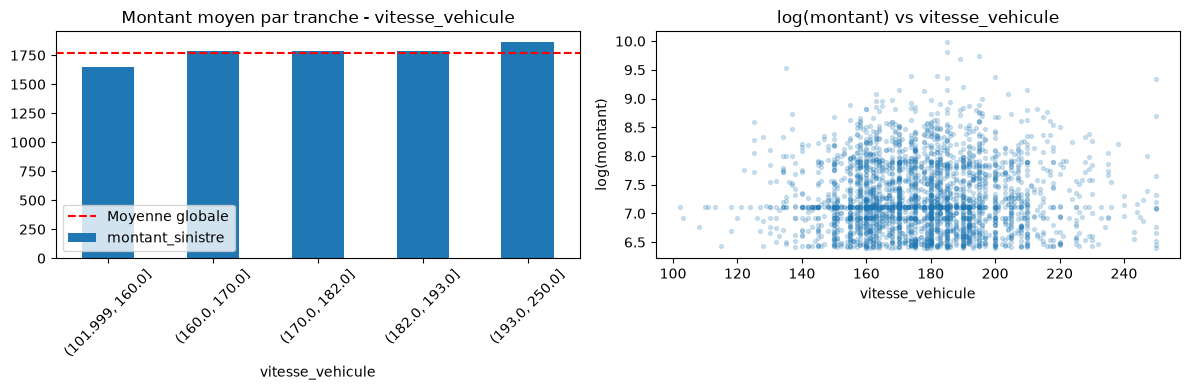

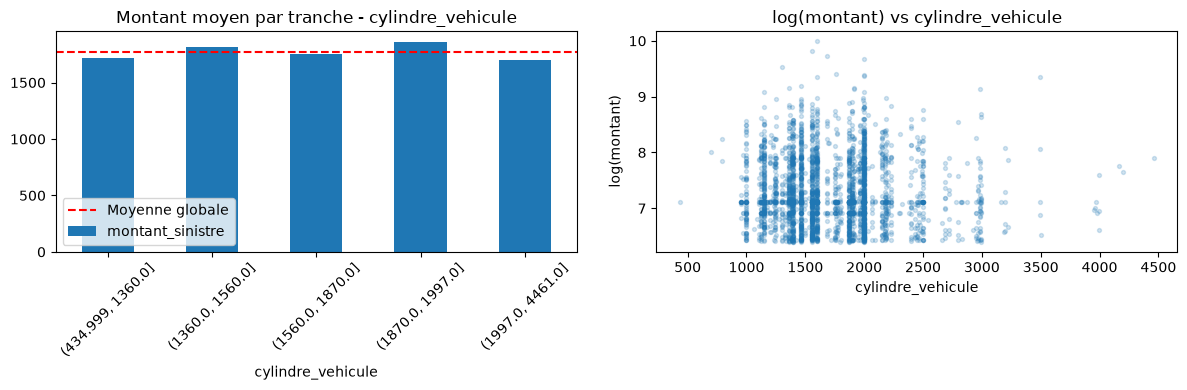

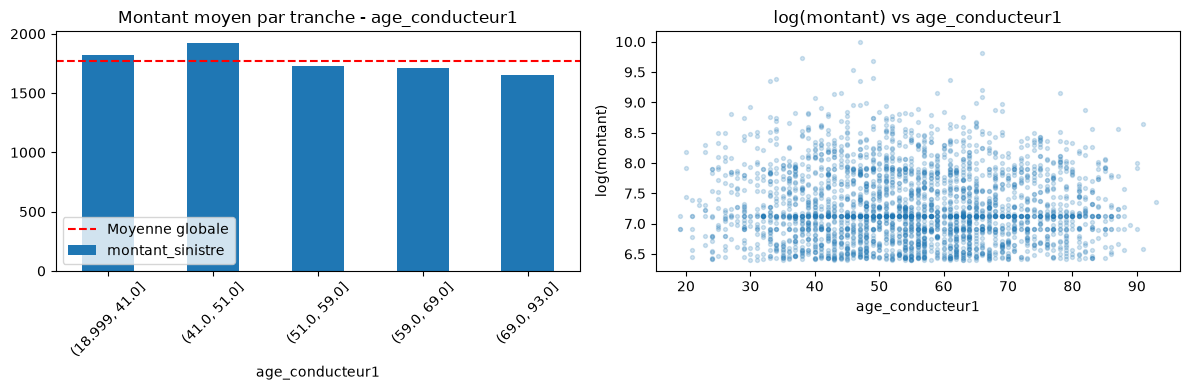

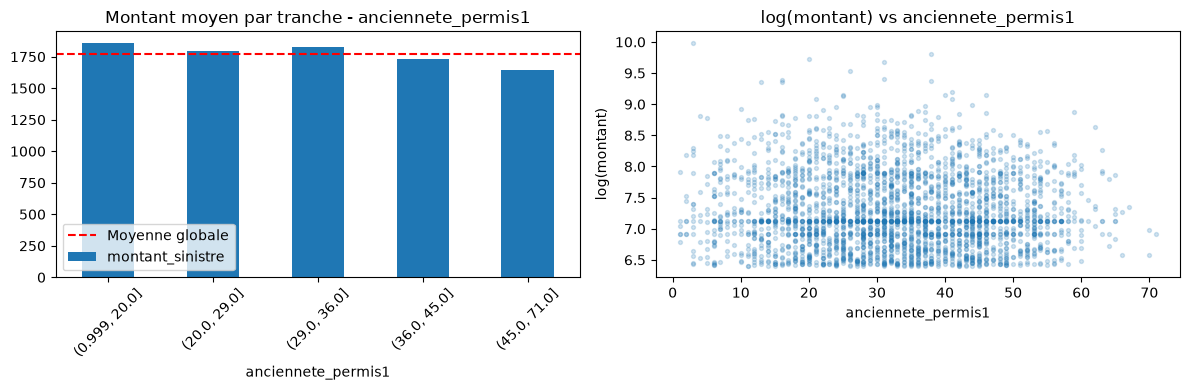

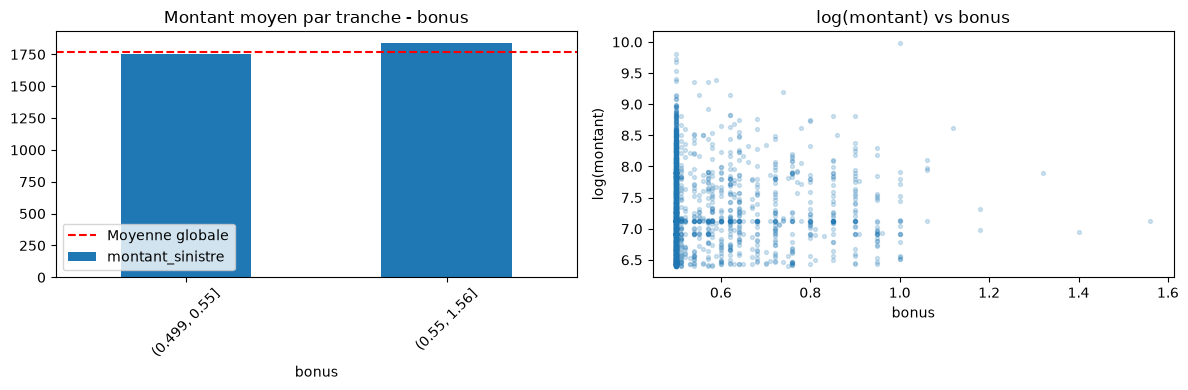

In [13]:
quanti_m = ["prix_vehicule", "anciennete_vehicule", "din_vehicule", "poids_vehicule",
            "vitesse_vehicule", "cylindre_vehicule", "age_conducteur1", "anciennete_permis1", "bonus"]

m = sinistres["montant_sinistre"]
log_m = np.log1p(m)

# 1. Corrélations : Pearson et Spearman, sur montant et log(montant)
corr = pd.DataFrame({
    "pearson_montant": sinistres[quanti_m].corrwith(m, method="pearson"),
    "pearson_log": sinistres[quanti_m].corrwith(log_m, method="pearson"),
    "spearman": sinistres[quanti_m].corrwith(m, method="spearman"),   # identique pour montant et log
}).round(3)
print(corr.sort_values("spearman", key=abs, ascending=False))

# 2. Montant moyen et log moyen par tranche (fait apparaître la forme de l'effet)
for c in quanti_m:
    tranches = pd.qcut(sinistres[c], 5, duplicates="drop")
    t = sinistres.groupby(tranches, observed=True).agg(
        montant_moyen=("montant_sinistre", "mean"),
        montant_median=("montant_sinistre", "median"),
        n=("montant_sinistre", "size"),
    )
    t["log_moyen"] = log_m.groupby(tranches, observed=True).mean()
    print(f"\n--- {c} ---\n{t.round(2)}")

# 3. Graphiques : montant moyen par tranche (gauche) et nuage de points en log (droite)
for c in quanti_m:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    tranches = pd.qcut(sinistres[c], 5, duplicates="drop")

    sinistres.groupby(tranches, observed=True)["montant_sinistre"].mean().plot(kind="bar", ax=axes[0], color="tab:blue")
    axes[0].axhline(m.mean(), color="red", ls="--", label="Moyenne globale")
    axes[0].set_title(f"Montant moyen par tranche - {c}")
    axes[0].tick_params(axis="x", rotation=45)
    axes[0].legend()

    axes[1].scatter(sinistres[c], log_m, alpha=0.2, s=8)
    axes[1].set_xlabel(c)
    axes[1].set_ylabel("log(montant)")
    axes[1].set_title(f"log(montant) vs {c}")

    plt.tight_layout()
    plt.show()

## Premier Entrainement 

In [20]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [ ]:
# 1. Données (mêmes variables que la régression, pour comparer)
sinistres["maxi"] = (sinistres["type_contrat"] == "Maxi").astype(int)
X = sinistres[["maxi", "anciennete_vehicule"]]
y = sinistres["montant_sinistre"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [21]:


params = {
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 30,
    "subsample": 0.8,
    "objective": "reg:squarederror",
}

# 1. Nombre d'arbres optimal, choisi par validation croisée sur le train uniquement
cv = xgb.cv(
    params={**params, "eta": params["learning_rate"]},
    dtrain=xgb.DMatrix(X_train, label=y_train),
    num_boost_round=1000,
    nfold=5,
    early_stopping_rounds=50,
    metrics="rmse",
    seed=42,
)
n_arbres = len(cv)
print("Nombre d'arbres retenu :", n_arbres)
print("RMSE en validation croisée :", round(cv["test-rmse-mean"].iloc[-1], 1))

# 2. Entraînement final sur tout le train
model_xgb = XGBRegressor(n_estimators=n_arbres, random_state=42, **params)
model_xgb.fit(X_train, y_train)

# 3. Évaluation sur le test
pred_xgb = model_xgb.predict(X_test)
naif = np.full(len(y_test), y_train.mean())

def evaluer(y_vrai, p):
    return {
        "R²": round(r2_score(y_vrai, p), 4),
        "RMSE": round(mean_squared_error(y_vrai, p) ** 0.5, 1),
        "MAE": round(mean_absolute_error(y_vrai, p), 1),
        "Total prédit / observé": round(p.sum() / y_vrai.sum(), 3),
    }

print(pd.DataFrame({
    "Moyenne globale": evaluer(y_test, naif),
    "XGBoost": evaluer(y_test, pred_xgb),
}).T)

# 4. Vérification du surapprentissage
pred_train = model_xgb.predict(X_train)
print("\nRMSE train :", round(mean_squared_error(y_train, pred_train) ** 0.5, 1),
      "| RMSE test :", round(mean_squared_error(y_test, pred_xgb) ** 0.5, 1))

Nombre d'arbres retenu : 48
RMSE en validation croisée : 1433.9
                     R²    RMSE    MAE  Total prédit / observé
Moyenne globale -0.0000  1490.5  951.9                   1.001
XGBoost          0.0173  1477.6  928.0                   0.999

RMSE train : 1438.7 | RMSE test : 1477.6


## Deuxième entrainement 

In [22]:
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, TweedieRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import RepeatedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [23]:

# Racine du projet : Path.cwd() si le notebook est à la racine, Path.cwd().parent s'il est dans notebooks/
RACINE = Path.cwd()
sys.path.insert(0, str(RACINE / "src"))   # nécessaire pour recharger le modèle de fréquence (module preparation)

TRAIN_PATH = RACINE / "data" / "raw" / "train.csv"
TEST_PATH = RACINE / "data" / "raw" / "test.csv"
MODELE_FREQ_PATH = RACINE / "models" / "rf_proba_model.pkl"
MODELE_MONTANT_PATH = RACINE / "models" / "montant_model.pkl"
SORTIE_PATH = RACINE / "data" / "predictions" / "prime_pure_test.csv"

- Modèle candidat

In [29]:
def selection(colonnes, transformateur="passthrough"):
    """Garde uniquement les colonnes voulues, en les transformant si besoin."""
    return ColumnTransformer([("sel", transformateur, colonnes)])

candidats = {
    # Références
    "0. Moyenne globale": DummyRegressor(strategy="mean"),

    # Régression sur les indicatrices de la formule = moyenne exacte de chaque formule
    "1. Moyenne par contrat": Pipeline([
        ("sel", selection(["type_contrat"], OneHotEncoder(handle_unknown="ignore"))),
        ("reg", LinearRegression()),
    ]),

    "2. Linéaire (maxi + ancienneté)": Pipeline([
        ("sel", selection(["maxi", "anciennete_vehicule"])),
        ("reg", LinearRegression()),
    ]),

    # Amélioration c : interaction Maxi × ancienneté
    "4. Linéaire + interaction": Pipeline([
        ("sel", selection(["maxi", "anciennete_vehicule", "maxi_x_anciennete"])),
        ("reg", LinearRegression()),
    ]),

    # Amélioration b : GLM Gamma, standard actuariel pour des montants positifs et asymétriques
    "5. GLM Gamma": Pipeline([
        ("sel", selection(["maxi", "anciennete_vehicule"], StandardScaler())),
        ("reg", TweedieRegressor(power=2, link="log", alpha=0, max_iter=1000)),
    ]),
}

# Amélioration a : écrêtement des gros sinistres au 99e percentile
NOM_ECRETE = "3. Linéaire écrêtée (P99)"

def entrainer(nom, X_tr, y_tr):
    """Entraîne un candidat et renvoie {modele, facteur}."""
    if nom == NOM_ECRETE:
        plafond = y_tr.quantile(0.99)
        y_ecrete = y_tr.clip(upper=plafond)
        modele = clone(candidats["2. Linéaire (maxi + ancienneté)"]).fit(X_tr, y_ecrete)
        facteur = y_tr.sum() / y_ecrete.sum()   # redistribue l'excédent retiré sur tous les contrats
        return {"modele": modele, "facteur": facteur}
    return {"modele": clone(candidats[nom]).fit(X_tr, y_tr), "facteur": 1.0}

def predire(artefact, X_new):
    """Montant attendu, corrigé par le facteur éventuel."""
    return artefact["modele"].predict(X_new) * artefact["facteur"]

noms = list(candidats) + [NOM_ECRETE]

In [39]:
from sklearn.preprocessing import PolynomialFeatures

degres = [2, 3, 4, 5]   # hyperparamètre p à tester

for p in degres:
    candidats[f"6. Polynomiale p={p}"] = Pipeline([
        ("sel", selection(["maxi", "anciennete_vehicule"])),
        ("poly", PolynomialFeatures(degree=p, include_bias=False)),   # crée x, x², ..., x^p et les interactions
        ("scaler", StandardScaler()),                                 # évite les écarts d'échelle entre x et x^p
        ("reg", LinearRegression()),
    ])

noms = list(candidats) + [NOM_ECRETE]   # mise à jour de la liste des modèles comparés
print(noms)

['0. Moyenne globale', '1. Moyenne par contrat', '2. Linéaire (maxi + ancienneté)', '4. Linéaire + interaction', '5. GLM Gamma', '6. Polynomiale p=2', '6. Polynomiale p=3', '6. Polynomiale p=4', '6. Polynomiale p=5', '3. Linéaire écrêtée (P99)']


In [42]:
from xgboost import XGBRegressor

for n in [50, 100, 200]:   # nombre d'arbres testé (48 avait été retenu précédemment)
    candidats[f"7. XGBoost n={n}"] = Pipeline([
        ("sel", selection(["maxi", "anciennete_vehicule"])),
        ("reg", XGBRegressor(
            n_estimators=n,
            learning_rate=0.03,
            max_depth=3,
            min_child_weight=30,
            subsample=0.8,
            objective="reg:squarederror",
            random_state=42,
        )),
    ])

noms = list(candidats) + [NOM_ECRETE]
print(noms)

['0. Moyenne globale', '1. Moyenne par contrat', '2. Linéaire (maxi + ancienneté)', '4. Linéaire + interaction', '5. GLM Gamma', '6. Polynomiale p=2', '6. Polynomiale p=3', '6. Polynomiale p=4', '6. Polynomiale p=5', '7. XGBoost n=50', '7. XGBoost n=100', '7. XGBoost n=200', '3. Linéaire écrêtée (P99)']


 - Comparaison Validation croisée

In [43]:
def variables_montant(df):
    out = pd.DataFrame(index=df.index)
    out["type_contrat"] = df["type_contrat"]
    out["maxi"] = (df["type_contrat"] == "Maxi").astype(int)
    out["anciennete_vehicule"] = df["anciennete_vehicule"].fillna(df["anciennete_vehicule"].median())
    out["maxi_x_anciennete"] = out["maxi"] * out["anciennete_vehicule"]
    return out

X = variables_montant(sinistres)
y = sinistres["montant_sinistre"]

assert X.columns.tolist() == ["type_contrat", "maxi", "anciennete_vehicule", "maxi_x_anciennete"], X.columns.tolist()
print("OK :", X.columns.tolist())

OK : ['type_contrat', 'maxi', 'anciennete_vehicule', 'maxi_x_anciennete']


In [66]:
def variables_montant(df):
    """Variables du modèle de montant (mêmes transformations à l'entraînement et à l'inférence)."""
    out = pd.DataFrame(index=df.index)
    out["type_contrat"] = df["type_contrat"]
    out["maxi"] = (df["type_contrat"] == "Maxi").astype(int)
    out["anciennete_vehicule"] = df["anciennete_vehicule"]
    out["vitesse_vehicule"] = df["vitesse_vehicule"]
    out["marque_vehicule"] = df["marque_vehicule"]
    return out

X = variables_montant(sinistres)
y = sinistres["montant_sinistre"]
print(X.columns.tolist())

['type_contrat', 'maxi', 'anciennete_vehicule', 'vitesse_vehicule', 'marque_vehicule']


In [70]:
# Jeux de variables à tester : ajoutez / supprimez librement
jeux = {
    "base":            {"num": ["maxi", "anciennete_vehicule"], "cat": []},
    "+ vitesse":       {"num": ["maxi", "anciennete_vehicule", "vitesse_vehicule"], "cat": []},
    "+ marque":        {"num": ["maxi", "anciennete_vehicule"], "cat": ["marque_vehicule"]},
    "+ vitesse+marque":{"num": ["maxi", "anciennete_vehicule", "vitesse_vehicule"], "cat": ["marque_vehicule"]},
}

def construire_prep(num, cat):
    transfo = [("num", SimpleImputer(strategy="median"), num)]
    if cat:
        transfo.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                              encoded_missing_value=-1, min_frequency=30), cat))
    return ColumnTransformer(transfo)

candidats = {
    "0. Moyenne globale": DummyRegressor(strategy="mean"),
    "1. Moyenne par contrat": Pipeline([
        ("sel", ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore"), ["type_contrat"])])),
        ("reg", LinearRegression()),
    ]),
}
for nom_jeu, v in jeux.items():
    candidats[f"XGBoost | {nom_jeu}"] = Pipeline([("prep", construire_prep(v["num"], v["cat"])), ("reg", xgb(100))])
    candidats[f"Random Forest | {nom_jeu}"] = Pipeline([("prep", construire_prep(v["num"], v["cat"])), ("reg", rf())])

noms = list(candidats)
print(len(noms), "modèles à comparer")

10 modèles à comparer


In [69]:
train.columns

Index(['index', 'id_client', 'id_vehicule', 'id_contrat', 'bonus',
       'type_contrat', 'duree_contrat', 'anciennete_info', 'freq_paiement',
       'paiement', 'utilisation', 'code_postal', 'conducteur2',
       'age_conducteur1', 'age_conducteur2', 'sex_conducteur1',
       'sex_conducteur2', 'anciennete_permis1', 'anciennete_permis2',
       'anciennete_vehicule', 'cylindre_vehicule', 'din_vehicule',
       'essence_vehicule', 'marque_vehicule', 'modele_vehicule',
       'debut_vente_vehicule', 'fin_vente_vehicule', 'vitesse_vehicule',
       'type_vehicule', 'prix_vehicule', 'poids_vehicule', 'nombre_sinistres',
       'montant_sinistre'],
      dtype='str')

In [71]:
# 5 plis × 3 répétitions : avec ~2 900 sinistres, un seul découpage ne suffit pas
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
scores = {nom: {"RMSE": [], "MAE": [], "Ratio total": []} for nom in noms}

for idx_tr, idx_te in rkf.split(X):
    X_tr, X_te = X.iloc[idx_tr], X.iloc[idx_te]
    y_tr, y_te = y.iloc[idx_tr], y.iloc[idx_te]
    for nom in noms:
        pred = predire(entrainer(nom, X_tr, y_tr), X_te)
        scores[nom]["RMSE"].append(mean_squared_error(y_te, pred) ** 0.5)
        scores[nom]["MAE"].append(mean_absolute_error(y_te, pred))
        scores[nom]["Ratio total"].append(pred.sum() / y_te.sum())

resultats = pd.DataFrame({
    nom: {
        "RMSE": np.mean(s["RMSE"]),
        "RMSE écart-type": np.std(s["RMSE"]),
        "MAE": np.mean(s["MAE"]),
        "Ratio total": np.mean(s["Ratio total"]),
    }
    for nom, s in scores.items()
}).T

rmse_naif = resultats.loc["0. Moyenne globale", "RMSE"]
resultats["Gain RMSE vs naïf (%)"] = (rmse_naif - resultats["RMSE"]) / rmse_naif * 100
resultats.sort_values("RMSE").round(3)

,RMSE,RMSE écart-type,MAE,Ratio total,Gain RMSE vs naïf (%)
Random Forest | + vitesse+marque,1442.338,151.764,927.813,1.001,0.972
XGBoost | base,1443.581,150.410,927.642,1.000,0.887
Random Forest | + marque,1443.601,151.618,928.729,1.001,0.885
XGBoost | + vitesse+marque,1444.453,149.838,929.774,1.001,0.827
Random Forest | base,1444.744,151.157,928.172,1.001,0.807
XGBoost | + marque,1444.911,149.665,928.809,1.001,0.795
Random Forest | + vitesse,1445.140,150.634,929.986,1.001,0.780
XGBoost | + vitesse,1445.162,150.483,929.652,1.000,0.778
1. Moyenne par contrat,1449.093,152.643,931.707,1.001,0.508
0. Moyenne globale,1456.496,148.552,953.811,1.001,0.000


- Choix du modèle final 

In [77]:

from sklearn.impute import SimpleImputer


RACINE = "C:/Users/papam/Documents/Cours_Cytech/ING3/Data Science/PricingPrimeAssurance"
TRAIN_PATH = f"{RACINE}/data/train.csv"
TEST_PATH = f"{RACINE}/data/test.csv"
PROBA_PATH = f"{RACINE}/inference_test/predictions_proba_test.csv"
MODELE_PATH = f"{RACINE}/models/xgb_montant_model.pkl"
SORTIE_PATH = f"{RACINE}/inference_test/prime_pure.csv"

VARIABLES = ["maxi", "anciennete_vehicule"]

# 1. Construction des variables (identique à l'entraînement et à l'inférence)
def variables_montant(df):
    return pd.DataFrame({
        "maxi": (df["type_contrat"] == "Maxi").astype(int),
        "anciennete_vehicule": df["anciennete_vehicule"],
    }, index=df.index)

# 2. Modèle retenu : même configuration qu'en validation croisée
modele_montant = Pipeline([
    ("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), VARIABLES)])),  # médiane apprise sur le train
    ("reg", XGBRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=30,
        subsample=0.8,
        objective="reg:squarederror",
        random_state=42,
    )),
])


- Entrainement final 

In [82]:

# 3. Entraînement final sur TOUS les sinistres de train.csv
train = pd.read_csv(TRAIN_PATH)
sinistres = train[(train["nombre_sinistres"] > 0) & (train["montant_sinistre"] > 0)]
modele_montant.fit(variables_montant(sinistres), sinistres["montant_sinistre"])
print("Entraîné sur", len(sinistres), "sinistres")

with open(MODELE_PATH, "wb") as f:
    pickle.dump(modele_montant, f)


Entraîné sur 2917 sinistres


In [83]:

# 4. Montant attendu pour chaque contrat du test
test = pd.read_csv(TEST_PATH, usecols=["index", "type_contrat", "anciennete_vehicule"])
test["montant_attendu"] = modele_montant.predict(variables_montant(test))

# 5. Prime pure = probabilité de sinistre × montant attendu
proba = pd.read_csv(PROBA_PATH)
col_proba = "proba_sinistre" if "proba_sinistre" in proba.columns else "proba"

df = proba.merge(test, on="index", how="left")
assert df["montant_attendu"].notna().all(), "Des index du fichier de probabilités sont absents de test.csv"
df["pred"] = df[col_proba] * df["montant_attendu"]

# 6. Sauvegarde : index + prime pure uniquement
df[["index", "pred"]].to_csv(SORTIE_PATH, index=False)
print("Fichier enregistré :", SORTIE_PATH)

# 7. Contrôles de cohérence
print(df.groupby("type_contrat")[[col_proba, "montant_attendu", "pred"]].mean().round(3))
print("Montant attendu moyen :", round(df["montant_attendu"].mean(), 1), "€ (train :", round(sinistres["montant_sinistre"].mean(), 1), "€)")
print("Prime pure moyenne    :", round(df["pred"].mean(), 2), "€")

Fichier enregistré : C:/Users/papam/Documents/Cours_Cytech/ING3/Data Science/PricingPrimeAssurance/inference_test/prime_pure.csv
              proba  montant_attendu     pred
type_contrat                                 
Maxi          0.074      1817.514038  136.189
Median1       0.030      1395.879028   42.718
Median2       0.034      1436.193970   48.863
Mini          0.022      1363.317993   31.069
Montant attendu moyen : 1671.3 € (train : 1771.8 €)
Prime pure moyenne    : 102.89 €
